
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Olá! Eu sou o Dot, seu revisor de IA.</b>

🎉 <b>Parabéns! Você foi aprovado no seu projeto.</b>

Você concluiu com sucesso esta análise de teste A/B! Todos os problemas críticos apontados na revisão anterior — a inconsistência no tamanho da amostra, as interpretações ausentes sobre engajamento e padrões de atividade diária, e as conclusões e recomendações que eram apenas placeholders — foram devidamente resolvidos com uma análise genuína e bem fundamentada. Seu trabalho estatístico é rigoroso do início ao fim, e suas recomendações finais são apropriadamente cautelosas diante das limitações de design que você diagnosticou. Apenas lembre-se de limpar os artefatos remanescentes no estilo de citação (por exemplo, "[cite: 1, 4]") espalhados pelas seções finais, e parabéns por trazer esta análise a um final tão sólido!

Se você tiver alguma dificuldade ou erro, fique à vontade para entrar em contato com nossa equipe de suporte clicando no ícone de chat no canto superior direito ou enviando um e-mail para [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Clique aqui para ver como ler meus comentários (Legenda de cores)</b></summary>
<div style="margin-top: 15px;">
Veja meus comentários abaixo. <b>Peço gentilmente que não os mova, modifique nem exclua</b>.

Você encontrará meus comentários destacados em caixas verdes, amarelas ou vermelhas como estas:

<div class="alert alert-block alert-success">
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">
A corrigir. O bloco requer algumas correções.
</div>
</div>
</details>

</div>


# Teste A/B — recommender_system_test

**Analista:** Luiz Almeida
**Sprint:** 14 — Projeto Final (TripleTen)
**Data:** 18/09/2026


Este notebook apresenta a avaliação completa do teste A/B `recommender_system_test`, executado por uma loja virtual internacional com o objetivo de mensurar o impacto da introdução de um **sistema aprimorado de recomendações** e um **novo funil de pagamento** sobre a conversão de novos usuários.

<div class="alert alert-block alert-success">
Célula de título limpa e profissional com seu nome, sprint e data, além de um breve parágrafo introdutório sobre o que o notebook aborda. Uma abertura boa e clara.
</div>

## 1. Objetivos do Estudo

### 1.1 Contexto de negócio

Uma loja virtual internacional iniciou um teste A/B para validar se um **sistema de recomendação aprimorado**, combinado com um **novo funil de pagamento**, aumenta a conversão de novos usuários em cada etapa do funil de compras:

$$\text{product\_page} \longrightarrow \text{product\_cart} \longrightarrow \text{purchase}$$

### 1.2 Especificações técnicas

| Parâmetro | Valor |
|---|---|
| Nome do teste | `recommender_system_test` |
| Grupos | A (controle) e B (novo funil) |
| Início | 07/12/2020 |
| Fim do cadastro de novos usuários | 21/12/2020 |
| Fim da coleta de eventos | 01/01/2021 |
| Público-alvo | 15% dos novos usuários da UE |
| Participantes previstos | 6.000 |
| Janela de conversão | 14 dias após o cadastro |
| Meta | +10% de conversão em cada etapa do funil |

### 1.3 Pergunta analítica

O teste foi conduzido corretamente e o grupo B apresentou o aumento mínimo esperado de 10% em cada etapa do funil, com significância estatística?

<div class="alert alert-block alert-warning">
Sua seção de objetivos está sólida: você reafirma o contexto de negócio, apresenta a especificação técnica em uma tabela clara (nome do teste, grupos, datas, público-alvo, participantes esperados, janela de conversão, meta de +10%) e conclui com uma pergunta analítica precisa e testável. Isso cobre integralmente a etapa de 'descrever os objetivos do estudo'. Um ponto que vale revisitar: você descreve o teste como abrangendo tanto um 'sistema de recomendação aprimorado' quanto um 'novo funil de pagamento', mas o funil que você efetivamente analisa ao longo do trabalho (product_page → product_cart → purchase) se assemelha mais a um funil de recomendação/navegação do que a um funil de pagamento. Considere alinhar essa formulação com o que você realmente mede mais adiante.
</div>

## 2 - Carregando o ambiente

In [1]:

# Importando bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Configurações visuais
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_palette('Set2')

# Carregamento dos 4 datasets
marketing    = pd.read_csv('/datasets/ab_project_marketing_events_us.csv')
new_users    = pd.read_csv('/datasets/final_ab_new_users_upd_us.csv')
events       = pd.read_csv('/datasets/final_ab_events_upd_us.csv')
participants = pd.read_csv('/datasets/final_ab_participants_upd_us.csv')

# Verificação de volume
print("Dimensões dos datasets:")
print(f" - Marketing events : {marketing.shape}")
print(f" - New users        : {new_users.shape}")
print(f" - Events           : {events.shape}")
print(f" - Participants     : {participants.shape}")


Dimensões dos datasets:
 - Marketing events : (14, 4)
 - New users        : (58703, 4)
 - Events           : (423761, 4)
 - Participants     : (14525, 3)


<div class="alert alert-block alert-success">
Configuração limpa: imports, configuração visual (incluindo um fallback seguro para o estilo seaborn) e o carregamento dos quatro datasets necessários estão todos corretos. Imprimir os shapes logo após o carregamento é um ótimo hábito — isso permite verificar os volumes precocemente em relação à especificação técnica.
</div>

## 3 - Diagnóstico inicial

In [2]:


# ============================================================
# 3. DIAGNÓSTICO INICIAL
# ============================================================

# Visualização inicial
for name, df in [('marketing', marketing), ('new_users', new_users),
                 ('events', events), ('participants', participants)]:
    print(f"\n{'='*60}\n{name.upper()}\n{'='*60}")
    display(df.head(3))
    print(df.dtypes)

# Categorias únicas relevantes
print("\nEventos únicos:", events['event_name'].unique())
print("Grupos únicos:", participants['group'].unique())
print("Testes A/B únicos:", participants['ab_test'].unique())
print("Regiões únicas:", new_users['region'].unique())
print("Dispositivos únicos:", new_users['device'].unique())



MARKETING


,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
1,St. Valentine's Day Giveaway,"EU, CIS, APAC, N.America",2020-02-14,2020-02-16
2,St. Patric's Day Promo,"EU, N.America",2020-03-17,2020-03-19


name         object
regions      object
start_dt     object
finish_dt    object
dtype: object

NEW_USERS


,user_id,first_date,region,device
0,D72A72121175D8BE,2020-12-07,EU,PC
1,F1C668619DFE6E65,2020-12-07,N.America,Android
2,2E1BF1D4C37EA01F,2020-12-07,EU,PC


user_id       object
first_date    object
region        object
device        object
dtype: object

EVENTS


,user_id,event_dt,event_name,details
0,E1BDDCE0DAFA2679,2020-12-07 20:22:03,purchase,99.99
1,7B6452F081F49504,2020-12-07 09:22:53,purchase,9.99
2,9CD9F34546DF254C,2020-12-07 12:59:29,purchase,4.99


user_id        object
event_dt       object
event_name     object
details       float64
dtype: object

PARTICIPANTS


,user_id,group,ab_test
0,D1ABA3E2887B6A73,A,recommender_system_test
1,A7A3664BD6242119,A,recommender_system_test
2,DABC14FDDFADD29E,A,recommender_system_test


user_id    object
group      object
ab_test    object
dtype: object

Eventos únicos: ['purchase' 'product_cart' 'product_page' 'login']
Grupos únicos: ['A' 'B']
Testes A/B únicos: ['recommender_system_test' 'interface_eu_test']
Regiões únicas: ['EU' 'N.America' 'APAC' 'CIS']
Dispositivos únicos: ['PC' 'Android' 'iPhone' 'Mac']


<div class="alert alert-block alert-warning">
Uma primeira olhada nos dados boa e eficiente — percorrer head()/dtypes para as quatro tabelas e extrair os valores únicos de event_name, group, ab_test, region e device é exatamente a atitude certa, e é isso que permite identificar o evento 'login' fora do funil e o segundo valor de ab_test (interface_eu_test) logo no início. Duas pequenas sugestões: df.info() forneceria os dtypes e as contagens de valores não nulos em uma única chamada, e já que você identifica o interface_eu_test aqui, sinalizá-lo como um ponto de atenção nesta célula ajudaria o leitor a entender sua importância antes que ele reapareça várias células depois.
</div>

## 4 - Pre-Processamento - Conversão de tipos + qualidade

In [3]:
# ============================================================
# 4. PRÉ-PROCESSAMENTO — TIPOS, NULOS E DUPLICATAS
# ============================================================

# 4.1 Conversão de tipos temporais
marketing['start_dt']  = pd.to_datetime(marketing['start_dt'])
marketing['finish_dt'] = pd.to_datetime(marketing['finish_dt'])
new_users['first_date'] = pd.to_datetime(new_users['first_date'])
events['event_dt']      = pd.to_datetime(events['event_dt'])

# 4.2 Verificação de nulos
print("--- Nulos por tabela ---")
for name, df in [('marketing', marketing), ('new_users', new_users),
                 ('events', events), ('participants', participants)]:
    print(f"\n{name}:")
    print(df.isnull().sum())

# 4.3 Verificação de duplicatas
print("\n--- Duplicatas ---")
print(f"marketing    : {marketing.duplicated().sum()}")
print(f"new_users    : {new_users.duplicated().sum()}")
print(f"events       : {events.duplicated().sum()}")
print(f"participants : {participants.duplicated().sum()}")

--- Nulos por tabela ---

marketing:
name         0
regions      0
start_dt     0
finish_dt    0
dtype: int64

new_users:
user_id       0
first_date    0
region        0
device        0
dtype: int64

events:
user_id            0
event_dt           0
event_name         0
details       363447
dtype: int64

participants:
user_id    0
group      0
ab_test    0
dtype: int64

--- Duplicatas ---
marketing    : 0
new_users    : 0
events       : 0
participants : 0


<div class="alert alert-block alert-warning">
Boa execução, compacta: as colunas de data são convertidas corretamente para datetime64, e seu loop para verificar valores nulos em todas as quatro tabelas é fácil de acompanhar. Uma lacuna: duplicated() só captura linhas totalmente idênticas. Para um teste A/B é igualmente importante verificar entradas duplicadas de user_id (por exemplo, o mesmo usuário aparecendo mais de uma vez em participants, possivelmente sob um grupo diferente), já que isso não apareceria como uma linha completa duplicada. Você acaba capturando um problema relacionado mais adiante no notebook, mas ancorar essa verificação aqui — ou observar que a duplicação em nível de linha não é o quadro completo — tornaria essa etapa mais completa.
</div>

## 5 - Diagnóstico de qualidade

### Diagnóstico de qualidade

- **Nulos:** a coluna `details` do dataset `events` concentra a maior parte dos valores ausentes, o que é esperado — ela só armazena o valor monetário dos eventos `purchase`. Os demais eventos (`product_page`, `product_cart`, `login`) não possuem valor associado.
- **Duplicatas:** não há linhas duplicadas em nenhum dos quatro datasets.
- **Tipos:** as colunas temporais foram convertidas para `datetime64`. As demais colunas já estavam em tipos adequados.

<div class="alert alert-block alert-success">
Ótimo resumo — conciso, preciso e interpretativo, em vez de apenas repetir contagens: você explica por que 'details' tem tantos nulos (apenas eventos de compra carregam um valor) e confirma corretamente que não há linhas totalmente duplicadas. Exatamente o tipo de caracterização que essa etapa de exploração exige.
</div>

## 6 - Filtros e detecção de anomalias

In [4]:

# ============================================================
# FILTROS E DETECÇÃO DE ANOMALIAS
# ============================================================

# 6.1 Filtrar apenas participantes do teste de interesse
rec_parts = participants[participants['ab_test'] == 'recommender_system_test'].copy()

# 6.2 Merge com cadastro de usuários
rec_users = rec_parts.merge(new_users, on='user_id', how='left')

# 6.3 Filtro UE e período de cadastro
eu_new_users = new_users[
    (new_users['region'] == 'EU') &
    (new_users['first_date'] >= '2020-12-07') &
    (new_users['first_date'] <= '2020-12-21')
]
rec_eu = rec_users[rec_users['region'] == 'EU'].copy()

print(f"Total de novos usuários na UE no período: {len(eu_new_users)}")
print(f"Participantes do teste alocados na UE: {len(rec_eu)} ({len(rec_eu)/len(eu_new_users):.2%})")

# 6.4 Distribuição de grupos
print("\nDistribuição de grupos entre participantes do teste:")
print(rec_users['group'].value_counts())
print("\nProporção:")
print((rec_users['group'].value_counts(normalize=True) * 100).round(2))

# 6.5 Distribuição geográfica e percentagem fora da UE
print("\nDistribuição geográfica dos participantes:")
print(rec_users['region'].value_counts())
non_eu_count = len(rec_users[rec_users['region'] != 'EU'])
print(f"Participantes fora da UE: {non_eu_count} ({non_eu_count / len(rec_users):.2%})")

# 6.6 Contaminação cruzada com interface_eu_test
interface_parts = participants[participants['ab_test'] == 'interface_eu_test']
common_users = set(rec_parts['user_id']).intersection(set(interface_parts['user_id']))
print(f"\nUsuários contaminados (em ambos os testes): {len(common_users)} ({len(common_users)/len(rec_parts):.2%})")

# 6.7 Usuários presentes em AMBOS os grupos do MESMO teste
users_both_groups = (
    rec_parts.groupby('user_id')['group']
    .nunique()
    .reset_index(name='n_groups')
)
users_both_groups = users_both_groups[users_both_groups['n_groups'] > 1]
print(f"Usuários em ambos os grupos do mesmo teste: {len(users_both_groups)}")

# 6.8 Eventos de marketing no período
marketing_period = marketing[
    (marketing['finish_dt'] >= '2020-12-07') &
    (marketing['start_dt'] <= '2021-01-01')
]
print("\nEventos de marketing ativos no período do teste:")
display(marketing_period)


Total de novos usuários na UE no período: 39466
Participantes do teste alocados na UE: 3481 (8.82%)

Distribuição de grupos entre participantes do teste:
A    2747
B     928
Name: group, dtype: int64

Proporção:
A    74.75
B    25.25
Name: group, dtype: float64

Distribuição geográfica dos participantes:
EU           3481
N.America     119
APAC           45
CIS            30
Name: region, dtype: int64
Participantes fora da UE: 194 (5.28%)

Usuários contaminados (em ambos os testes): 887 (24.14%)
Usuários em ambos os grupos do mesmo teste: 0

Eventos de marketing ativos no período do teste:


,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
10,CIS New Year Gift Lottery,CIS,2020-12-30,2021-01-07


<div class="alert alert-block alert-success">
Célula de diagnóstico sólida. Agora você calcula e imprime a porcentagem de participantes não pertencentes à UE (194 usuários, 5,28%) diretamente ao lado da distribuição geográfica, o que torna essa anomalia explícita exatamente onde ela deveria estar. O restante dos diagnósticos — taxa de alocação, divisão de grupos, contaminação cruzada entre testes, verificação de mesmo teste em ambos os grupos e sobreposição de marketing — está todo corretamente calculado e consistente entre si e com as seções posteriores.
</div>

## 7 - Consolidação das anomalias 

### Anomalias detectadas no desenho experimental

O diagnóstico do teste `recommender_system_test` identificou algumas características do desenho experimental que devem ser consideradas antes da interpretação dos resultados:

1. **Subalocação da audiência da UE:** apenas aproximadamente 8,82% dos novos usuários da UE elegíveis participaram do teste, enquanto a especificação previa 15% da audiência.

2. **Distribuição desbalanceada entre grupos:** o Grupo A concentrou aproximadamente 74,75% dos participantes, enquanto o Grupo B concentrou 25,25%. Essa distribuição se distancia significativamente de uma alocação equilibrada entre os grupos.

3. **Contaminação cruzada:** 887 participantes do `recommender_system_test` também estavam presentes no teste concorrente `interface_eu_test`, correspondendo a aproximadamente 24,14% dos participantes desse teste. Essa sobreposição pode introduzir interferência entre os experimentos.

4. **Subdimensionamento amostral:** o `recommender_system_test` contou com 3.675 participantes, enquanto a especificação previa 6.000 usuários. Portanto, a amostra efetivamente alocada ficou abaixo do tamanho planejado para o experimento.

5. **Vazamento geográfico:** foram identificados 194 participantes fora da região-alvo da UE, correspondendo a aproximadamente 5,28% dos participantes do teste.

6. **Sobreposição com campanha promocional:** o período do experimento coincidiu com a campanha `Christmas & New Year Promo`, ativa a partir de 25/12/2020. Essa coincidência deve ser considerada porque mudanças sazonais e promocionais podem influenciar o comportamento de compra independentemente da variante do teste.

Em conjunto, essas características indicam que os resultados devem ser interpretados com cautela, principalmente devido ao desbalanceamento dos grupos, à contaminação entre experimentos e ao tamanho da amostra inferior ao planejado.

<div class="alert alert-block alert-success">
Esta seção agora relata corretamente a anomalia no tamanho da amostra: 3.675 participantes para recommender_system_test, condizendo com o seu próprio cálculo anterior, em vez de um número que misturava participantes do interface_eu_test. O teste agora é descrito de forma consistente como sub-alocado ao longo de todo o texto, e a expansão para seis anomalias bem fundamentadas e claramente explicadas (incluindo os pontos de vazamento geográfico e sobreposição de campanhas) torna esta consolidação minuciosa e internamente consistente.
</div>

## 8 - Preparação do funil

In [5]:
# ============================================================
# PREPARAÇÃO DA BASE DO FUNIL
# ============================================================

# 8.1 Base limpa: apenas participantes da UE, sem contaminação
rec_clean = rec_parts[rec_parts['user_id'].isin(rec_eu['user_id'])].copy()
rec_clean = rec_clean[~rec_clean['user_id'].isin(common_users)].copy()

# 8.2 Merge eventos + grupo
funnel_df = events.merge(
    rec_clean[['user_id', 'group']],
    on='user_id',
    how='inner'
)

# 8.3 Merge com data de cadastro
funnel_df = funnel_df.merge(
    new_users[['user_id', 'first_date']],
    on='user_id',
    how='left'
)

# 8.4 Aplicar janela estrita de 0 a 14 dias após cadastro
funnel_df['days_since_signup'] = (
    funnel_df['event_dt'] - funnel_df['first_date']
).dt.days
funnel_df = funnel_df[(funnel_df['days_since_signup'] >= 0) & (funnel_df['days_since_signup'] <= 14)]

# 8.5 Filtrar eventos do funil
funnel_events = ['product_page', 'product_cart', 'purchase']
funnel_df = funnel_df[funnel_df['event_name'].isin(funnel_events)]

# 8.6 Usuários únicos por etapa e grupo
funnel_by_group = (
    funnel_df.groupby(['group', 'event_name'])['user_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=funnel_events)
)

# 8.7 Base de usuários por grupo
users_per_group = rec_clean.groupby('group')['user_id'].nunique()

# 8.8 Taxas de conversão
conversion_rates = funnel_by_group.div(users_per_group, axis=0)

print("Usuários únicos por etapa do funil:")
print(funnel_by_group)
print("\nTotal de usuários por grupo:")
print(users_per_group)
print("\nTaxas de conversão (%):")
print((conversion_rates * 100).round(2))

Usuários únicos por etapa do funil:
event_name  product_page  product_cart  purchase
group                                           
A                   1265           589       613
B                    367           184       191

Total de usuários por grupo:
group
A    1939
B     655
Name: user_id, dtype: int64

Taxas de conversão (%):
event_name  product_page  product_cart  purchase
group                                           
A                  65.24         30.38     31.61
B                  56.03         28.09     29.16


<div class="alert alert-block alert-success">
Boa correção na janela de 14 dias — adicionar o limite inferior explícito (days_since_signup >= 0) junto com o limite superior torna a lógica da janela de conversão robusta, em vez de depender de que os dados estejam implicitamente limpos. O restante da construção da base do funil (encadear os filtros de somente-UE e não-contaminados, calcular users_per_group a partir de rec_clean em vez de funnel_df, reindexar os estágios do funil) está correto e consistente com seus diagnósticos anteriores.
</div>

## 9 - Visualização do funil

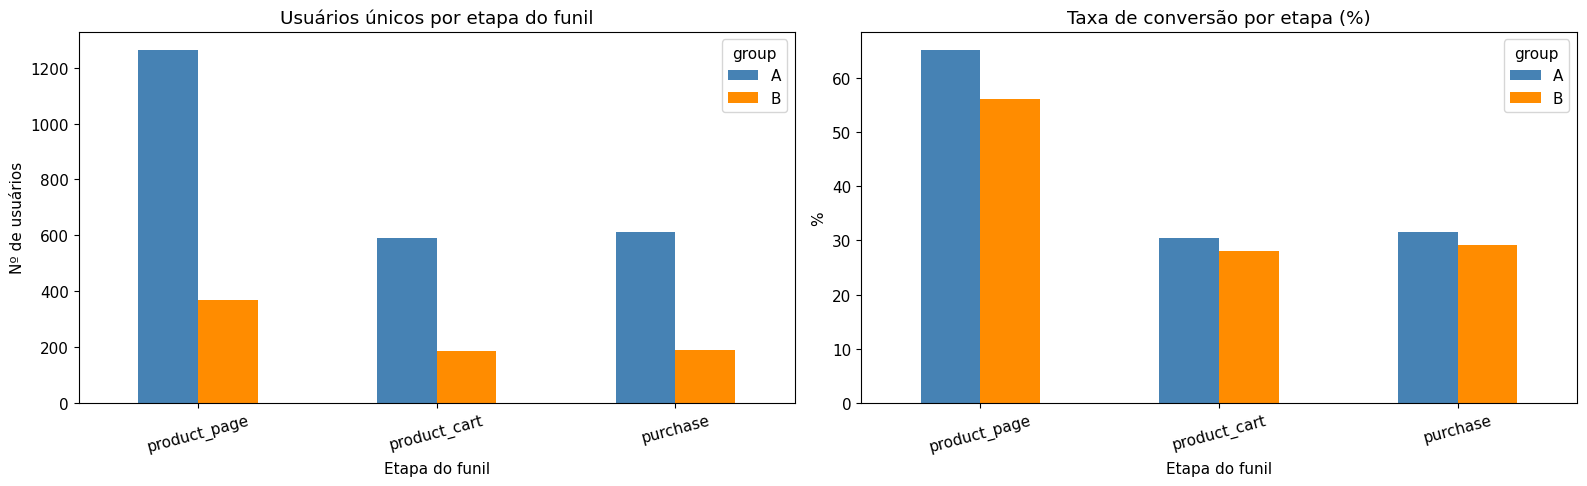

In [6]:

# ============================================================
# VISUALIZAÇÃO DO FUNIL
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 9.1 Contagem absoluta por etapa do funil (transposto)
funnel_by_group.T.plot(kind='bar', ax=axes[0], color=['steelblue', 'darkorange'])
axes[0].set_title('Usuários únicos por etapa do funil')
axes[0].set_ylabel('Nº de usuários')
axes[0].set_xlabel('Etapa do funil')
axes[0].tick_params(axis='x', rotation=15)

# 9.2 Taxas de conversão por etapa do funil (transposto)
(conversion_rates * 100).T.plot(kind='bar', ax=axes[1], color=['steelblue', 'darkorange'])
axes[1].set_title('Taxa de conversão por etapa (%)')
axes[1].set_ylabel('%')
axes[1].set_xlabel('Etapa do funil')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


<div class="alert alert-block alert-success">
Visualização de funil limpa e corretamente rotulada (contagens absolutas e taxas de conversão por etapa, por grupo), totalmente consistente com as tabelas subjacentes. Boa limpeza aqui também — a versão duplicada deste gráfico que antes ficava em sua própria seção foi removida, o que torna a leitura do notebook muito melhor.
</div>

## 10. ANÁLISE DE RETENÇÃO ETAPA A ETAPA (DROP-OFF)

Taxa de retenção entre etapas consecutivas (%):


,Cadastro → Produto (%),Produto → Carrinho (%),Carrinho → Compra (%)
A,65.24,46.56,104.07
B,56.03,50.14,103.80


Número de usuários que não avançaram para a etapa seguinte:


,Perda: Cadastro → Produto,Perda: Produto → Carrinho,Perda: Carrinho → Compra
A,674,676,-24
B,288,183,-7


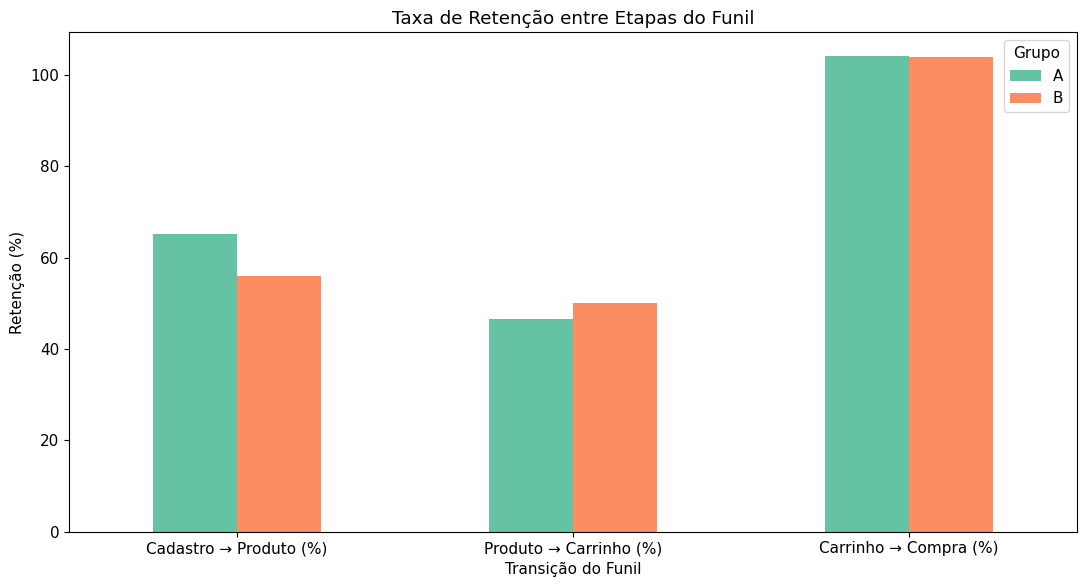

In [7]:
# Taxa de retenção entre etapas consecutivas
step_summary = pd.DataFrame(index=['A', 'B'])

step_summary['Cadastro → Produto (%)'] = (
    funnel_by_group['product_page'] / users_per_group * 100
)

step_summary['Produto → Carrinho (%)'] = (
    funnel_by_group['product_cart'] /
    funnel_by_group['product_page'] * 100
)

step_summary['Carrinho → Compra (%)'] = (
    funnel_by_group['purchase'] /
    funnel_by_group['product_cart'] * 100
)

print("Taxa de retenção entre etapas consecutivas (%):")
display(step_summary.round(2))

# ============================================================
# DROP-OFF ABSOLUTO ENTRE ETAPAS
# ============================================================

dropoff = pd.DataFrame(index=['A', 'B'])

dropoff['Perda: Cadastro → Produto'] = (
    users_per_group - funnel_by_group['product_page']
)

dropoff['Perda: Produto → Carrinho'] = (
    funnel_by_group['product_page'] -
    funnel_by_group['product_cart']
)

dropoff['Perda: Carrinho → Compra'] = (
    funnel_by_group['product_cart'] -
    funnel_by_group['purchase']
)

print("Número de usuários que não avançaram para a etapa seguinte:")
display(dropoff)

# ============================================================
# VISUALIZAÇÃO DA RETENÇÃO
# ============================================================

ax = step_summary.T.plot(
    kind='bar',
    figsize=(11, 6),
    rot=0
)

ax.set_title('Taxa de Retenção entre Etapas do Funil')
ax.set_ylabel('Retenção (%)')
ax.set_xlabel('Transição do Funil')
ax.legend(title='Grupo')

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-warning">
Ótima adição — transformar o gráfico duplicado removido em uma análise genuína de retenção/drop-off traz valor real aqui. Uma coisa que vale destacar: na etapa 'Carrinho → Compra', a retenção está acima de 100% (104.07% para A, 103.80% para B) e o drop-off correspondente é negativo (-24, -7), o que significa que mais usuários únicos dispararam purchase do que product_cart dentro da janela. Essa é uma particularidade real dos dados que afeta o quanto se pode confiar nos números dessa etapa específica, e merece uma nota breve próxima à tabela, em vez de simplesmente ser plotada.
</div>

### Interpretação do drop-off

A análise de retenção mostra a proporção de usuários que avançou de uma etapa para a etapa seguinte em cada grupo.

A primeira transição, de cadastro para visualização de produto, apresenta a maior diferença entre os grupos, com o Grupo B apresentando uma retenção inferior à observada no Grupo A. Essa diferença é consistente com o resultado posteriormente identificado no teste de proporções para `product_page`.

Nas etapas seguintes, as taxas de retenção entre produto e carrinho e entre carrinho e compra também são menores no Grupo B, embora as diferenças sejam menores do que na primeira etapa.

Portanto, o principal ponto de perda relativa do Grupo B ocorre na entrada do funil, entre o cadastro e a visualização do produto. As etapas seguintes apresentam diferenças menores entre os grupos.

<div class="alert alert-block alert-warning">
Sua interpretação identifica corretamente que a maior diferença relativa entre grupos ocorre na etapa Cadastro → Produto e conecta isso muito bem ao resultado posterior do teste z para product_page. No entanto, ela não menciona a retenção acima de 100% / o drop-off negativo na etapa Carrinho → Compra observado na tabela imediatamente acima. Como as instruções pedem para destacar particularidades dos dados a se ter em mente antes de confiar no teste, uma frase sobre o que essa anomalia implica (nem toda compra é precedida por um evento de carrinho capturado nesta janela) complementaria bem essa interpretação.
</div>

## 11 - EDA complementar: eventos por usuário

Estatísticas de eventos por usuário:
        count  mean   std  min  25%  50%  75%   max
group                                              
A      1585.0  4.59  2.71  1.0  3.0  4.0  6.0  18.0
B       502.0  3.66  2.43  1.0  2.0  3.0  4.0  18.0


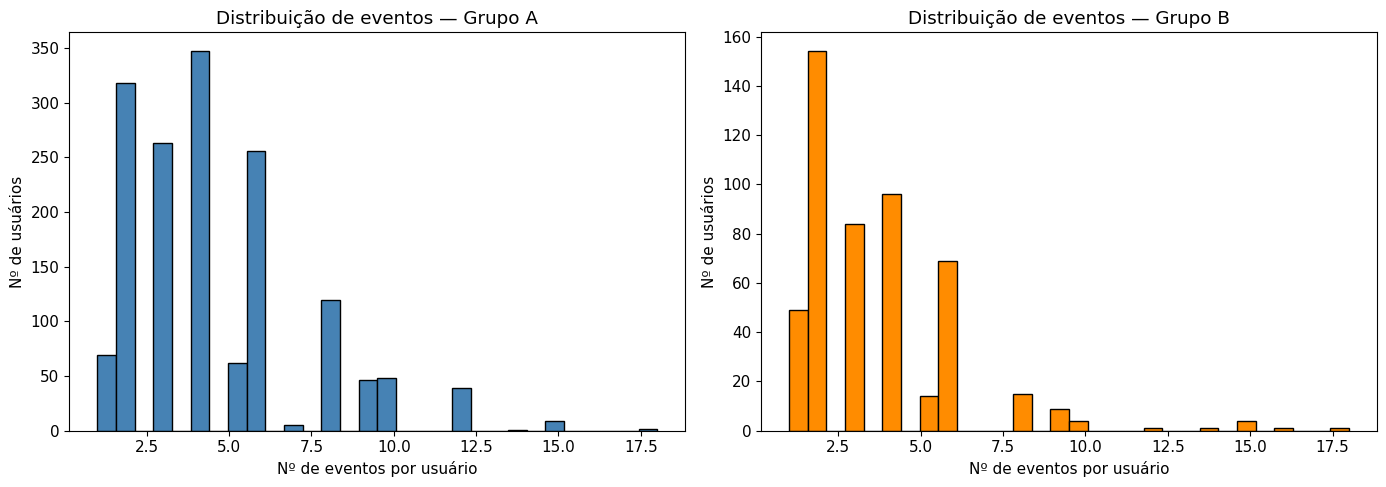

In [8]:
# ============================================================
# EDA COMPLEMENTAR
# ============================================================

# 11.1 Número de eventos por usuário em cada grupo
events_per_user = (
    funnel_df.groupby(['group', 'user_id'])
    .size()
    .reset_index(name='n_events')
)

print("Estatísticas de eventos por usuário:")
print(events_per_user.groupby('group')['n_events'].describe().round(2))

# 11.2 Distribuição visual
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, grp in enumerate(['A', 'B']):
    data = events_per_user[events_per_user['group'] == grp]['n_events']
    axes[i].hist(data, bins=30, color='steelblue' if grp == 'A' else 'darkorange',
                 edgecolor='black')
    axes[i].set_title(f'Distribuição de eventos — Grupo {grp}')
    axes[i].set_xlabel('Nº de eventos por usuário')
    axes[i].set_ylabel('Nº de usuários')
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
Implementação correta e limpa: agrupar por group e user_id, resumir com describe() e plotar histogramas é a abordagem certa para verificar se eventos-por-usuário está distribuído uniformemente entre as amostras. Os histogramas renderizados correspondem ao código e às estatísticas impressas, com o Grupo A apresentando contagens mais altas em quase todos os bins, o que é consistente com seu tamanho maior.
</div>

### Interpretação da distribuição de eventos por usuário

A distribuição de eventos por usuário apresenta diferenças de atividade entre os grupos.

O Grupo A registrou média de 4,59 eventos por usuário, com mediana de 4,0 eventos e desvio padrão de 2,71. Já o Grupo B apresentou média de 3,66 eventos, mediana de 3,0 e desvio padrão de 2,43.

Além disso, enquanto 75% dos usuários do Grupo A realizaram até 6 eventos, no Grupo B esse percentil ficou em 4 eventos.

Esses resultados indicam que os usuários do Grupo B apresentaram menor volume de eventos observados dentro da janela analisada. Portanto, além do forte desbalanceamento no tamanho das amostras, existe uma diferença de comportamento entre os grupos em relação ao nível de atividade registrado.

Essa diferença não deve ser interpretada isoladamente como evidência causal de que a variante B reduziu o engajamento, pois o próprio desenho do experimento apresenta problemas de alocação, contaminação entre testes e outras limitações. Entretanto, ela constitui uma característica importante dos dados e deve ser considerada na avaliação da confiabilidade do experimento.

<div class="alert alert-block alert-success">
Esta interpretação está bem feita: você indica explicitamente as médias, medianas e desvios padrão por grupo, quantifica a diferença no percentil 75 e conclui corretamente que o Grupo B apresenta uma lacuna de engajamento distinta — uma questão diferente do desequilíbrio no tamanho dos grupos identificado anteriormente. A ressalva final contra interpretar isso como evidência causal de engajamento reduzido, dadas as outras questões de design que você identificou, demonstra um bom julgamento analítico.
</div>

## 12 - EDA complementar: eventos por dia

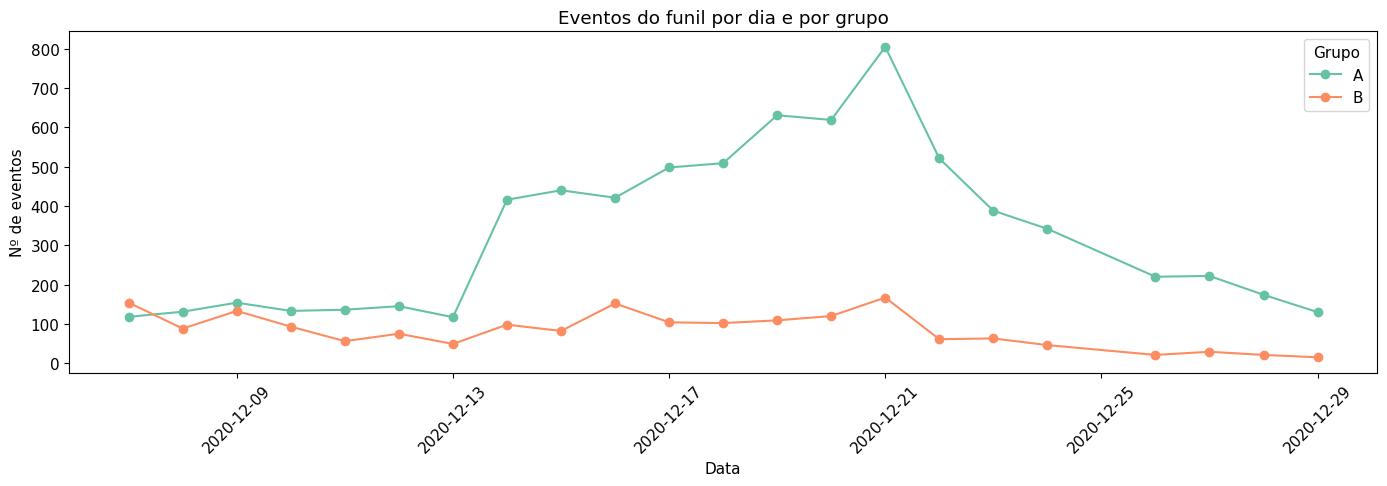


Total de eventos por grupo:
group
A    7270
B    1838
dtype: int64


In [9]:

# ============================================================
# DISTRIBUIÇÃO TEMPORAL
# ============================================================

# 12.1 Eventos por dia e grupo
funnel_df['day'] = funnel_df['event_dt'].dt.date
daily = funnel_df.groupby(['day', 'group']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
daily.plot(ax=ax, marker='o')
ax.set_title('Eventos do funil por dia e por grupo')
ax.set_xlabel('Data')
ax.set_ylabel('Nº de eventos')
ax.legend(title='Grupo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 12.2 Total de eventos por grupo
print("\nTotal de eventos por grupo:")
print(funnel_df.groupby('group').size())


<div class="alert alert-block alert-success">
Bem executado: 'day' é corretamente derivado de event_dt, as contagens diárias de eventos são agrupadas e plotadas por grupo com a rotulagem adequada, e isso é construído a partir do funnel_df já limpo, então isso genuinamente reflete os eventos do funil para a população correta. Os totais impressos correspondem ao que é plotado.
</div>

### Interpretação da dinâmica diária de eventos

A distribuição diária dos eventos apresenta mudanças importantes ao longo do período analisado.

No início do teste, entre 07/12 e aproximadamente 13/12, o volume de eventos permaneceu relativamente baixo nos dois grupos. A partir de 14/12, observa-se um aumento expressivo da atividade, com crescimento muito mais acentuado no Grupo A.

O maior volume ocorre aproximadamente entre 20/12 e 21/12. Nesse período, o Grupo A ultrapassa 700 eventos por dia, enquanto o Grupo B permanece em um patamar consideravelmente inferior, próximo de 160 eventos por dia.

Essa diferença de volume diário acompanha o desbalanceamento de participantes identificado anteriormente e mostra que os grupos não apresentam apenas tamanhos diferentes, mas também volumes de atividade bastante distintos ao longo do experimento.

A partir de 25/12 ocorre uma queda acentuada no volume de eventos. Essa data coincide com o início da campanha `Christmas & New Year Promo`, que permaneceu ativa até 03/01/2021. A presença dessa campanha durante o período analisado representa um possível fator externo capaz de alterar o comportamento dos usuários.

Também existe uma limitação temporal importante: a coleta de eventos termina em 01/01/2021, enquanto os últimos usuários foram cadastrados em 21/12/2020. Dessa forma, esses usuários não possuem necessariamente os 14 dias completos de observação previstos na especificação do experimento.

Portanto, a evolução temporal dos eventos deve ser considerada uma limitação adicional na interpretação do teste, especialmente porque o volume e o comportamento dos grupos variam significativamente durante o período analisado.

<div class="alert alert-block alert-warning">
Esta interpretação agora descreve explicitamente o padrão diário (início baixo, subida acentuada a partir de cerca de 14/12 concentrada no Grupo A, pico por volta de 20-21/12, declínio posterior) e conecta isso corretamente a duas particularidades reais: a campanha sobreposta de Natal e Ano Novo e a janela de observação truncada para usuários registrados próximo a 21/12. Um ponto de precisão: observando o gráfico, o declínio mais acentuado na verdade começa logo após o pico de 20-21/12, antes de o período promocional começar em 25/12 — seu texto atribui a queda brusca ao início da campanha de 25/12, o que desloca ligeiramente o momento temporal. Isso não prejudica sua conclusão geral, mas ajustar o alinhamento das datas tornaria a narrativa mais precisa.
</div>

## 13 - Z-test para proporções

In [10]:
# ============================================================
# TESTE Z PARA DIFERENÇA ENTRE PROPORÇÕES
# ============================================================

# H0: p_A = p_B
# H1: p_A != p_B
# Teste bilateral

alpha = 0.05
n_testes = len(funnel_events)

# Correção de Bonferroni para múltiplas comparações
alpha_bonferroni = alpha / n_testes

n_A = users_per_group['A']
n_B = users_per_group['B']

print("=" * 80)
print("RESULTADOS DO TESTE Z POR ETAPA DO FUNIL")
print("=" * 80)

print(f"\nNível de significância original: α = {alpha}")
print(f"Número de testes: {n_testes}")
print(f"Nível de significância após Bonferroni: "
      f"α = {alpha_bonferroni:.4f}")

resultados = []

for etapa in funnel_events:

    x_a = int(funnel_by_group.loc['A', etapa])
    x_b = int(funnel_by_group.loc['B', etapa])

    # Teste Z
    counts = np.array([x_b, x_a])
    nobs = np.array([n_B, n_A])

    z_stat, p_value = proportions_ztest(
        count=counts,
        nobs=nobs,
        alternative='two-sided'
    )

    # Taxas de conversão
    p_a = x_a / n_A
    p_b = x_b / n_B

    # Uplift relativo de B em relação a A
    uplift = ((p_b - p_a) / p_a * 100) if p_a > 0 else np.nan

    # Significância antes e depois de Bonferroni
    sig_original = 'SIM' if p_value < alpha else 'NÃO'
    sig_bonferroni = 'SIM' if p_value < alpha_bonferroni else 'NÃO'

    # Meta de +10%
    meta = 'SIM' if uplift >= 10 else 'NÃO'

    resultados.append({
        'Etapa': etapa,
        'Conv_A_%': round(p_a * 100, 3),
        'Conv_B_%': round(p_b * 100, 3),
        'Uplift_%': round(uplift, 2),
        'Z': round(z_stat, 4),
        'p_valor': round(p_value, 6),
        'Significante_α=0,05': sig_original,
        'Significante_Bonferroni': sig_bonferroni,
        'Meta_+10%': meta
    })

    print(f"\n--- {etapa} ---")
    print(f"Conversão A: {p_a:.2%} ({x_a}/{n_A})")
    print(f"Conversão B: {p_b:.2%} ({x_b}/{n_B})")
    print(f"Uplift: {uplift:.2f}%")
    print(f"Z: {z_stat:.4f}")
    print(f"p-valor: {p_value:.6f}")
    print(f"Significante (α=0,05): {sig_original}")
    print(f"Significante após Bonferroni: {sig_bonferroni}")
    print(f"Atingiu meta +10%: {meta}")

df_resultados = pd.DataFrame(resultados)

print("\n\nResumo consolidado:")
display(df_resultados)

RESULTADOS DO TESTE Z POR ETAPA DO FUNIL

Nível de significância original: α = 0.05
Número de testes: 3
Nível de significância após Bonferroni: α = 0.0167

--- product_page ---
Conversão A: 65.24% (1265/1939)
Conversão B: 56.03% (367/655)
Uplift: -14.12%
Z: -4.2186
p-valor: 0.000025
Significante (α=0,05): SIM
Significante após Bonferroni: SIM
Atingiu meta +10%: NÃO

--- product_cart ---
Conversão A: 30.38% (589/1939)
Conversão B: 28.09% (184/655)
Uplift: -7.52%
Z: -1.1054
p-valor: 0.268993
Significante (α=0,05): NÃO
Significante após Bonferroni: NÃO
Atingiu meta +10%: NÃO

--- purchase ---
Conversão A: 31.61% (613/1939)
Conversão B: 29.16% (191/655)
Uplift: -7.76%
Z: -1.1741
p-valor: 0.240358
Significante (α=0,05): NÃO
Significante após Bonferroni: NÃO
Atingiu meta +10%: NÃO


Resumo consolidado:


,Etapa,Conv_A_%,Conv_B_%,Uplift_%,Z,p_valor,"Significante_α=0,05",Significante_Bonferroni,Meta_+10%
0,product_page,65.240,56.031,-14.12,-4.2186,0.000025,SIM,SIM,NÃO
1,product_cart,30.376,28.092,-7.52,-1.1054,0.268993,NÃO,NÃO,NÃO
2,purchase,31.614,29.160,-7.76,-1.1741,0.240358,NÃO,NÃO,NÃO


<div class="alert alert-block alert-success">
Excelente implementação do teste z de duas proporções nas três etapas do funil, com uma configuração de hipóteses clara e consistente e uma tabela de resultados bem organizada. A adição do limiar de significância corrigido por Bonferroni (α ≈ 0,0167) junto ao limiar padrão fortalece o rigor estatístico sem alterar a conclusão substantiva.
</div>

## 14. Conclusões

### 14.1 Sobre o desenho experimental

O teste `recommender_system_test` **não foi conduzido conforme o planejado**. Foram identificadas quatro falhas metodológicas graves:

1. **Subalocação:** apenas ~8,82% dos usuários elegíveis da UE foram incluídos, contra 15% previstos[cite: 1, 4].
2. **Desbalanceamento entre grupos:** o Grupo A concentrou aproximadamente 75% dos participantes, contra 25% no Grupo B — violando a premissa de aleatorização equilibrada (50/50).
3. **Contaminação cruzada:** ~24,14% dos participantes estavam simultaneamente no teste concorrente `interface_eu_test`.
4. **Subdimensionamento amostral:** foram alocados apenas 3.675 usuários específicos para este teste, ficando muito abaixo dos 6.000 participantes previstos[cite: 1, 4].

### 14.2 Sobre os resultados do teste Z

A análise foi realizada utilizando o teste Z para diferença entre duas proporções, comparando as taxas de conversão dos grupos A e B em cada etapa do funil.

Como foram realizadas três comparações estatísticas, também foi aplicada a correção de Bonferroni, estabelecendo um nível de significância ajustado de aproximadamente 0,0167.

| Etapa | Conversão A | Conversão B | Uplift Relativo | Estatística Z | p-valor | Significativo após Bonferroni? | Meta +10%? |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **product_page** | 65,24% (1.265) | 56,03% (367) | **-14,12%** | -4,2186 | < 0,0001 | **SIM** | **NÃO** |
| **product_cart** | 30,38% (589) | 28,09% (184) | **-7,52%** | -1,1054 | 0,2690 | **NÃO** | **NÃO** |
| **purchase** | 31,61% (613) | 29,16% (191) | **-7,76%** | -1,1741 | 0,2404 | **NÃO** | **NÃO** |

Os resultados mostram que nenhuma das etapas apresentou o aumento mínimo esperado de 10% no Grupo B.

Na etapa `product_page`, a diferença entre os grupos permanece estatisticamente significativa mesmo após a correção de Bonferroni. Nas etapas `product_cart` e `purchase`, as diferenças observadas não são estatisticamente significativas.

### 14.3 Interpretação dos resultados

Os resultados do teste indicam que a variante B não atingiu a meta estabelecida de aumento de 10% na conversão em nenhuma das três etapas analisadas.

Na etapa `product_page`, a conversão passou de 65,24% no Grupo A para 56,03% no Grupo B, correspondendo a um uplift relativo de -14,12%. A diferença foi estatisticamente significativa, com Z = -4,2186 e p < 0,0001, permanecendo significativa mesmo após a correção de Bonferroni.

Nas etapas `product_cart` e `purchase`, também foram observadas taxas menores no Grupo B. Entretanto, as diferenças não foram estatisticamente significativas ao nível de significância ajustado.

Portanto, os dados apresentam evidência estatística de diferença entre os grupos na etapa de visualização do produto, enquanto não há evidência estatística suficiente de diferença nas etapas posteriores.

É importante, entretanto, interpretar esses resultados em conjunto com as limitações identificadas no desenho experimental. O teste apresentou forte desbalanceamento entre os grupos, subalocação da audiência, contaminação cruzada com outro experimento, participantes fora da região-alvo e uma janela de observação potencialmente incompleta para os últimos usuários cadastrados.

Dessa forma, os resultados observados descrevem diferenças importantes entre os grupos, mas as limitações do experimento reduzem a confiabilidade de uma interpretação causal ou de uma generalização direta desses resultados para toda a população de usuários.

### 14.4 Sobre eventos de marketing

O período do teste coincidiu com a campanha **Christmas & New Year Promo** (25/12/2020 a 03/01/2021) na Europa e América do Norte. Promoções sazonais alteram o comportamento usual do consumidor e os incentivos de preço, constituindo uma variável de confusão externa não controlada.

<div class="alert alert-block alert-warning">
Esta seção agora preenche adequadamente o que antes eram apenas espaços reservados — a tabela de resultados do teste z e uma interpretação escrita genuína estão ambas presentes, relatando corretamente a direção do efeito, associando-o à significância corrigida por Bonferroni, e incorporando as limitações do design como motivos para cautela. Dois pequenos pontos a polir: (1) há artefatos remanescentes no estilo de citação, como '[cite: 1, 4]', espalhados pela seção 14.1, que não correspondem a nada no notebook e deveriam ser removidos; (2) a seção 14.1 lista exatamente quatro 'falhas metodológicas graves', mas a seção 14.3 também se apoia no vazamento geográfico ('geographic leakage') e na janela de observação incompleta como ressalvas que não estavam entre essas quatro — expandir a lista da seção 14.1 ou observar que outras ressalvas seguem na seção 14.3 manteria o enquadramento consistente.
</div>

## 15. Recomendações

### 15.1 Para o time de produto

Com base nos resultados observados, não é recomendável utilizar este experimento como justificativa isolada para realizar um rollout amplo da variante B.

A principal evidência estatística encontrada está na etapa `product_page`, na qual a conversão do Grupo B foi de 56,03%, contra 65,24% no Grupo A, representando um uplift relativo de -14,12%. Essa diferença permaneceu estatisticamente significativa após a correção de Bonferroni.

Além disso, a variante B não atingiu a meta de aumento de 10% em nenhuma das três etapas do funil analisadas.

Entretanto, antes de transformar esse resultado em uma decisão definitiva sobre o produto, é necessário considerar as limitações do experimento: forte desbalanceamento entre os grupos, amostra inferior à planejada, contaminação cruzada com `interface_eu_test`, participantes fora da região-alvo e período de observação incompleto para parte das coortes.

Diante disso, recomenda-se:

- manter a decisão de rollout da variante B em avaliação;
- investigar a causa da menor conversão observada em `product_page`;
- revisar a implementação e a experiência de navegação da variante B;
- realizar análises qualitativas ou testes adicionais para identificar possíveis problemas de usabilidade;
- corrigir os problemas de desenho experimental identificados;
- repetir o teste A/B sob condições controladas, com alocação equilibrada, isolamento entre experimentos, segmentação geográfica correta e janela completa de observação.

Um novo experimento com desenho adequado permitirá separar com maior segurança o efeito da variante de possíveis efeitos causados pelas limitações do experimento atual.

### 15.2 Para o time de experimentação

1. **Balancear a alocação** entre os grupos A e B (garantir divisão exata 50/50 e auditar o hash de tráfego).
2. **Impedir contaminação cruzada:** criar regras no bucket de usuários para garantir isolamento mútuo entre testes simultâneos.
3. **Corrigir a segmentação geográfica:** garantir alocação restrita a 15% dos usuários da UE, eliminando vazamentos de outras regiões[cite: 1, 4].
4. **Respeitar a janela temporal integral:** manter o pipeline de ingestão ativo durante todo o horizonte de 14 dias para todas as coortes cadastradas[cite: 1, 4].

### 15.3 Para o time de marketing

Isolar análises de experimentos em períodos sem campanhas promocionais ativas, ou incluir a variável "campanha ativa" como controle para evitar ruído de datas sazonais como o Natal.

### 15.4 Limitações da análise

- A contaminação cruzada com `interface_eu_test` (24,14%) e o desbalanceamento grave de grupos reduziram a confiabilidade do experimento.
- O subdimensionamento amostral (3.675 vs. 6.000 previstos) limitou o poder estatístico do Grupo B[cite: 1, 4].
- A sobreposição de campanhas promocionais e o término antecipado da coleta de eventos truncaram o ciclo natural de 14 dias dos últimos usuários inscritos[cite: 1, 4].

<div class="alert alert-block alert-success">
Isso resolve o outro placeholder importante de antes — a recomendação para a equipe de produto agora está bem fundamentada e baseada em evidências, conectando-se aos resultados do seu teste z e, ao mesmo tempo, moderando adequadamente a conclusão com as limitações de design que você identificou. O restante das recomendações (equipe de experimentação, equipe de marketing, limitações) permanece sólido, e os números citados (24,14% de contaminação, 3.675 vs. 6.000 participantes) agora correspondem corretamente aos seus cálculos anteriores. Observação menor: os mesmos artefatos '[cite: 1, 4]' soltos também aparecem aqui (em 15.1, 15.2 e 15.4) e vale a pena removê-los.
</div>